#DataSet

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

from sklearn.preprocessing import StandardScaler

In [ ]:
data = load_breast_cancer()
print(type(data))
print(data.keys())

data.target_names

print(data.data.shape)
print(data.target.shape)

print(data.feature_names)
print(data.target_names)

df=pd.DataFrame(data.data,columns=data.feature_names)

df['target']=data.target
df


<class 'sklearn.utils._bunch.Bunch'>
dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])
(569, 30)
(569,)
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0


#EDA


In [ ]:
df

df.describe()
df.info()
df.isnull().sum()

df[df['target']==1].describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,357.000000,357.000000,357.000000,357.000000,357.000000,357.000000,357.000000,357.000000,357.000000,357.000000,...,357.000000,357.000000,357.000000,357.000000,357.000000,357.000000,357.000000,357.000000,357.000000,357.0
mean,12.146524,17.914762,78.075406,462.790196,0.092478,0.080085,0.046058,0.025717,0.174186,0.062867,...,23.515070,87.005938,558.899440,0.124959,0.182673,0.166238,0.074444,0.270246,0.079442,1.0
std,1.780512,3.995125,11.807438,134.287118,0.013446,0.033750,0.043442,0.015909,0.024807,0.006747,...,5.493955,13.527091,163.601424,0.020013,0.092180,0.140368,0.035797,0.041745,0.013804,0.0
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.051850,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156600,0.055210,1.0
25%,11.080000,15.150000,70.870000,378.200000,0.083060,0.055620,0.020310,0.015020,0.158000,0.058530,...,19.580000,78.270000,447.100000,0.110400,0.112000,0.077080,0.051040,0.240600,0.070090,1.0
50%,12.200000,17.390000,78.180000,458.400000,0.090760,0.075290,0.037090,0.023440,0.171400,0.061540,...,22.820000,86.920000,547.400000,0.125400,0.169800,0.141200,0.074310,0.268700,0.077120,1.0
75%,13.370000,19.760000,86.100000,551.100000,0.100700,0.097550,0.059990,0.032510,0.189000,0.065760,...,26.510000,96.590000,670.000000,0.137600,0.230200,0.221600,0.097490,0.298300,0.085410,1.0
max,17.850000,33.810000,114.600000,992.100000,0.163400,0.223900,0.410800,0.085340,0.274300,0.095750,...,41.780000,127.100000,1210.000000,0.200600,0.584900,1.252000,0.175000,0.422800,0.148600,1.0


#Train-TestSplit

In [ ]:
X=df.iloc[:,:-1]
y=df.iloc[:,-1]

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

Scaler=StandardScaler()
X_train=Scaler.fit_transform(X_train)
X_test=Scaler.transform(X_test)



#Logistic Regression

In [ ]:
"class LogisticRegression:
  def __init__(self,epoch,learning_rate):
        self.epoch=epoch
        self.learning_rate=learning_rate

  def  sigmoid(self,z):
    return 1/(1+np.exp(-z))


  def fit(self,X_train,y_train):
    self.intercept=0
    self.coeff=np.zeros((X_train.shape[1],1))

    y_train=y_train.to_numpy().reshape(y_train.shape[0],1)

    for i in range (self.epoch):
      z=self.intercept+np.dot(X_train,self.coeff)
      y_hat=self.sigmoid(z)

      self.coeff=self.coeff-self.learning_rate*np.dot(X_train.T,(y_hat-y_train))/X_train.shape[0]
      self.intercept=self.intercept-self.learning_rate*np.sum(y_hat-y_train)/X_train.shape[0]


  def predict(self,X_test):
    ans=self.intercept+np.dot(X_test,self.coeff)
    ans=self.sigmoid(ans)

    return ans


model = LogisticRegression(
    epoch=1000,
    learning_rate=0.01
)



model.fit(X_train, y_train)

y_prob = model.predict(X_test)

print(y_prob[:10])

y_pred_03 = np.where(y_prob > 0.3, 1, 0)
y_pred_05 = np.where(y_prob > 0.5, 1, 0)
y_pred_07 = np.where(y_prob > 0.7, 1, 0)

y_pred_03 = y_pred_03.ravel()
y_pred_05 = y_pred_05.ravel()
y_pred_07 = y_pred_07.ravel()

TP = np.sum((y_pred_03 == 1) & (y_test == 1))
TN = np.sum((y_pred_03 == 0) & (y_test == 0))
FP = np.sum((y_pred_03 == 1) & (y_test == 0))
FN = np.sum((y_pred_03 == 0) & (y_test == 1))
print(f"TP: {TP}, TN: {TN}, FP: {FP}, FN: {FN}")

precision_03 = TP / (TP + FP)
recall_03 = TP / (TP + FN)

print(f"Precision (0.3): {precision_03}")
print(f"Recall (0.3): {recall_03}")



print("Accuracy:", accuracy_score(y_test, y_pred_05))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_05))
print("Precision:", precision_score(y_test, y_pred_05))
print("Recall:", recall_score(y_test, y_pred_05))
print("F1:", f1_score(y_test, y_pred_05))


sk_model = SklearnLogisticRegression()
sk_model.fit(X_train, y_train)
sk_y_pred = sk_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, sk_y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, sk_y_pred))
print("Precision:", precision_score(y_test, sk_y_pred))
print("Recall:", recall_score(y_test, sk_y_pred))
print("F1:", f1_score(y_test, sk_y_pred))











SyntaxError: unterminated string literal (detected at line 1) (431593055.py, line 1)

In [ ]:

iris = load_iris()
print(type(iris))
print(iris.keys())

iris.target_names

print(iris.data.shape)
print(iris.target.shape)

print(iris.feature_names)
print(iris.target_names)

df=pd.DataFrame(iris.data,columns=iris.feature_names)


df



#Multiclassification

In [ ]:

X=iris.data
y=iris.target

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)




def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)

    exp_z = np.exp(z)

    total = np.sum(exp_z, axis=1, keepdims=True)

    probabilities = exp_z / total

    return probabilities


class LogisticRegression:
  def __init__(self,epoch,learning_rate):
        self.epoch=epoch
        self.learning_rate=learning_rate




  def fit(self,X_train,y_train):
    n_classes=np.unique(y_train).shape[0]
    Y = np.eye(n_classes)[y_train]
    self.intercept=np.zeros((n_classes))
    self.coeff=np.zeros((X_train.shape[1],n_classes))



    for i in range (self.epoch):
      z=self.intercept+np.dot(X_train,self.coeff)
      Y_hat=softmax(z)

      self.coeff=self.coeff-self.learning_rate*np.dot(X_train.T,(Y_hat-Y))/X_train.shape[0]
      self.intercept=self.intercept-self.learning_rate*np.mean(Y_hat-Y,axis=0)


  def predict(self,X_test):
    ans=self.intercept+np.dot(X_test,self.coeff)
    ans=softmax(ans)

    return np.argmax(ans,axis=1)



model = LogisticRegression(
    epoch=1000,
    learning_rate=0.01
)



model.fit(X_train, y_train)

y = model.predict(X_test)


print("Accuracy:", accuracy_score(y_test, y))


##Decision Trees


In [ ]:
model1 = DecisionTreeClassifier(max_depth=1)

model1.fit(X_train, y_train)

train_pred = model1.predict(X_train)
test_pred = model1.predict(X_test)

print("Train accuracy:", accuracy_score(y_train, train_pred))
print("Test accuracy:", accuracy_score(y_test, test_pred))

model2 = DecisionTreeClassifier(max_depth=3)

model2.fit(X_train, y_train)

train_pred = model2.predict(X_train)
test_pred = model2.predict(X_test)

print("Train accuracy:", accuracy_score(y_train, train_pred))
print("Test accuracy:", accuracy_score(y_test, test_pred))

model3 = DecisionTreeClassifier(max_depth=10)

model3.fit(X_train, y_train)

train_pred = model3.predict(X_train)
test_pred = model3.predict(X_test)

print("Train accuracy:", accuracy_score(y_train, train_pred))
print("Test accuracy:", accuracy_score(y_test, test_pred))



##my implementation

In [ ]:

X=iris.data
y=iris.target

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)



def gini(y):
    classes, counts = np.unique(y, return_counts=True)

    probabilities = counts / len(y)

    gini_value = 1 - np.sum(probabilities ** 2)

    return gini_value

def split_gini(y_left, y_right):

    total_samples = len(y_left) + len(y_right)

    left_weight = len(y_left) / total_samples
    right_weight = len(y_right) / total_samples

    gini_left = gini(y_left)
    gini_right = gini(y_right)

    weighted_gini = (
        left_weight * gini_left
        + right_weight * gini_right
    )

    return weighted_gini


def split_data(X, y, threshold):

    left_mask = X <= threshold
    right_mask = X > threshold

    X_left = X[left_mask]
    y_left = y[left_mask]

    X_right = X[right_mask]
    y_right = y[right_mask]

    return X_left, y_left, X_right, y_right



def find_best_split(X, y):

    best_gini = float("inf")
    best_threshold = None
    best_feature = None

    n_features = X.shape[1]

    for feature in range(n_features):

        feature_values = X[:, feature]

        sorted_values = np.sort(feature_values)

        thresholds = []

        for i in range(len(sorted_values) - 1):

            threshold = (
                sorted_values[i] + sorted_values[i + 1]
            ) / 2

            thresholds.append(threshold)

        for threshold in thresholds:

            X_feature = X[:, feature]

            left_mask = X_feature <= threshold
            right_mask = X_feature > threshold

            y_left = y[left_mask]
            y_right = y[right_mask]

            if len(y_left) == 0 or len(y_right) == 0:
                continue

            weighted_gini = split_gini(
                y_left,
                y_right
            )

            if weighted_gini < best_gini:

                best_gini = weighted_gini
                best_threshold = threshold
                best_feature = feature

    return best_feature, best_threshold, best_gini



def majority_class(y):

    classes, counts = np.unique(y, return_counts=True)

    majority_index = np.argmax(counts)

    return classes[majority_index]




def should_stop(y, depth, max_depth):

    if depth >= max_depth:
        return True

    if len(np.unique(y)) == 1:
        return True

    return False

def build_tree(X, y, depth, max_depth):

    if should_stop(y, depth, max_depth):

        prediction = majority_class(y)

        return {
            "prediction": prediction
        }

    best_feature, best_threshold, best_gini = find_best_split(
        X, y
    )

    if best_threshold is None:

        prediction = majority_class(y)

        return {
            "prediction": prediction
        }

    X_feature = X[:, best_feature]

    left_mask = X_feature <= best_threshold
    right_mask = X_feature > best_threshold

    X_left = X[left_mask]
    y_left = y[left_mask]

    X_right = X[right_mask]
    y_right = y[right_mask]

    left_subtree = build_tree(
        X_left,
        y_left,
        depth + 1,
        max_depth
    )

    right_subtree = build_tree(
        X_right,
        y_right,
        depth + 1,
        max_depth
    )

    return {
        "feature": best_feature,
        "threshold": best_threshold,
        "left": left_subtree,
        "right": right_subtree
    }



def predict_one(node, x):

    if "prediction" in node:
        return node["prediction"]

    if x <= node["threshold"]:
        return predict_one(node["left"], x)

    else:
        return predict_one(node["right"], x)



tree = build_tree(
    X_train,
    y_train,
    depth=0,
    max_depth=3
)

def predict_one(node, x):

    if "prediction" in node:
        return node["prediction"]

    feature = node["feature"]
    threshold = node["threshold"]

    if x[feature] <= threshold:
        return predict_one(node["left"], x)

    else:
        return predict_one(node["right"], x)


def predict(tree, X):

    predictions = []

    for x in X:
        prediction = predict_one(tree, x)
        predictions.append(prediction)

    return np.array(predictions)



y_pred = predict(tree, X_test)

correct = np.sum(y_pred == y_test)

accuracy = correct / len(y_test)

print("Accuracy:", accuracy)

##Random Forest

In [ ]:
def bootstrap_sample(X, y):

    indices = np.random.choice(
        len(X),
        size=len(X),
        replace=True
    )

    X_sample = X[indices]
    y_sample = y[indices]

    return X_sample, y_sample


X_sample, y_sample = bootstrap_sample(X_train, y_train)

print(X_sample.shape)
print(y_sample.shape)



def gini(y):
    classes, counts = np.unique(y, return_counts=True)

    probabilities = counts / len(y)

    gini_value = 1 - np.sum(probabilities ** 2)

    return gini_value

def split_gini(y_left, y_right):

    total_samples = len(y_left) + len(y_right)

    left_weight = len(y_left) / total_samples
    right_weight = len(y_right) / total_samples

    gini_left = gini(y_left)
    gini_right = gini(y_right)

    weighted_gini = (
        left_weight * gini_left
        + right_weight * gini_right
    )

    return weighted_gini


def split_data(X, y, threshold):

    left_mask = X <= threshold
    right_mask = X > threshold

    X_left = X[left_mask]
    y_left = y[left_mask]

    X_right = X[right_mask]
    y_right = y[right_mask]

    return X_left, y_left, X_right, y_right



def find_best_split(X, y,maxfeatures):

    best_gini = float("inf")
    best_threshold = None
    best_feature = None
    n_features=X.shape[1]

    features = np.random.choice(
    n_features,
    size=maxfeatures,
    replace=False
)

    for feature in features:

        feature_values = X[:, feature]

        sorted_values = np.sort(feature_values)

        thresholds = []

        for i in range(len(sorted_values) - 1):

            threshold = (
                sorted_values[i] + sorted_values[i + 1]
            ) / 2

            thresholds.append(threshold)

        for threshold in thresholds:

            X_feature = X[:, feature]

            left_mask = X_feature <= threshold
            right_mask = X_feature > threshold

            y_left = y[left_mask]
            y_right = y[right_mask]

            if len(y_left) == 0 or len(y_right) == 0:
                continue

            weighted_gini = split_gini(
                y_left,
                y_right
            )

            if weighted_gini < best_gini:

                best_gini = weighted_gini
                best_threshold = threshold
                best_feature = feature

    return best_feature, best_threshold, best_gini



def majority_class(y):

    classes, counts = np.unique(y, return_counts=True)

    majority_index = np.argmax(counts)

    return classes[majority_index]




def should_stop(y, depth, max_depth):

    if depth >= max_depth:
        return True

    if len(np.unique(y)) == 1:
        return True

    return False

def build_tree(X, y, depth, max_depth,maxfeatures):

    if should_stop(y, depth, max_depth):

        prediction = majority_class(y)

        return {
            "prediction": prediction
        }

    best_feature, best_threshold, best_gini = find_best_split(
        X, y,maxfeatures
    )

    if best_threshold is None:

        prediction = majority_class(y)

        return {
            "prediction": prediction
        }

    X_feature = X[:, best_feature]

    left_mask = X_feature <= best_threshold
    right_mask = X_feature > best_threshold

    X_left = X[left_mask]
    y_left = y[left_mask]

    X_right = X[right_mask]
    y_right = y[right_mask]

    left_subtree = build_tree(
        X_left,
        y_left,
        depth + 1,
        max_depth,maxfeatures
    )

    right_subtree = build_tree(
        X_right,
        y_right,
        depth + 1,
        max_depth,maxfeatures
    )

    return {
        "feature": best_feature,
        "threshold": best_threshold,
        "left": left_subtree,
        "right": right_subtree
    }









def predict_one(node, x):

    if "prediction" in node:
        return node["prediction"]

    feature = node["feature"]
    threshold = node["threshold"]

    if x[feature] <= threshold:
        return predict_one(node["left"], x)

    else:
        return predict_one(node["right"], x)


def predict(tree, X):

    predictions = []

    for x in X:
        prediction = predict_one(tree, x)
        predictions.append(prediction)

    return np.array(predictions)



def build_forest(X, y, n_trees, max_depth, maxfeatures):

    forest = []

    for i in range(n_trees):

        X_sample, y_sample = bootstrap_sample(X, y)

        tree = build_tree(
            X_sample,
            y_sample,
            depth=0,
            max_depth=max_depth,
            maxfeatures=maxfeatures
        )

        forest.append(tree)

    return forest



forest = build_forest(
    X_train,
    y_train,
    n_trees=5,
    max_depth=3,
    maxfeatures=2
)

def predict_forest(forest, X):

    all_predictions = []

    for tree in forest:

        predictions = predict(tree, X)

        all_predictions.append(predictions)

    all_predictions = np.array(all_predictions)

    final_predictions = []

    for i in range(X.shape[0]):

        votes = all_predictions[:, i]

        counts = np.bincount(votes)

        prediction = np.argmax(counts)

        final_predictions.append(prediction)

    return np.array(final_predictions)


y_pred = predict_forest(forest, X_test)

correct = np.sum(y_pred == y_test)

accuracy = correct / len(y_test)

print("Accuracy:", accuracy)

##KNN


In [ ]:
import numpy as np


# --------------------------------------------------
# 1. Calculate Euclidean distance
# --------------------------------------------------

def euclidean_distance(x1, x2):

    difference = x1 - x2

    squared_difference = difference ** 2

    sum_squared_difference = np.sum(squared_difference)

    distance = np.sqrt(sum_squared_difference)

    return distance


# --------------------------------------------------
# 2. Calculate distance from one test point
#    to every training point
# --------------------------------------------------

def calculate_distances(X_train, x_test):

    distances = []

    for x_train in X_train:

        distance = euclidean_distance(
            x_train,
            x_test
        )

        distances.append(distance)

    return distances


# --------------------------------------------------
# 3. Find K nearest neighbors
# --------------------------------------------------

def get_nearest_neighbors(distances, k):

    sorted_indices = np.argsort(distances)

    nearest_indices = sorted_indices[:k]

    return nearest_indices


# --------------------------------------------------
# 4. Majority voting
# --------------------------------------------------

def majority_vote(neighbor_labels):

    counts = np.bincount(neighbor_labels)

    prediction = np.argmax(counts)

    return prediction


# --------------------------------------------------
# 5. Predict one test point
# --------------------------------------------------

def predict_one(X_train, y_train, x_test, k):

    distances = calculate_distances(
        X_train,
        x_test
    )

    nearest_indices = get_nearest_neighbors(
        distances,
        k
    )

    # y_train is a Pandas Series,
    # so use iloc for position-based indexing.
    # to_numpy() converts it into a NumPy array.

    neighbor_labels = y_train.iloc[
        nearest_indices
    ].to_numpy()

    prediction = majority_vote(
        neighbor_labels
    )

    return prediction


# --------------------------------------------------
# 6. Predict all test points
# --------------------------------------------------

def predict(X_train, y_train, X_test, k):

    predictions = []

    for x_test in X_test:

        prediction = predict_one(
            X_train,
            y_train,
            x_test,
            k
        )

        predictions.append(prediction)

    return np.array(predictions)

def standardize(X_train, X_test):

    mean = np.mean(X_train, axis=0)

    std = np.std(X_train, axis=0)

    X_train_scaled = (X_train - mean) / std

    X_test_scaled = (X_test - mean) / std

    return X_train_scaled, X_test_scaled



X_train_scaled, X_test_scaled = standardize(
    X_train,
    X_test
)

for k in [1, 3, 5, 7, 9]:

    y_pred = predict(
        X_train_scaled,
        y_train,
        X_test_scaled,
        k
    )

    correct = np.sum(y_pred == y_test)

    total = len(y_test)

    accuracy = correct / total

    print("k =", k, "accuracy =", accuracy)

##Naive Bayes

In [ ]:
X = [
    ["Sunny", "Hot"],
    ["Sunny", "Cool"],
    ["Rainy", "Cool"],
    ["Rainy", "Hot"],
    ["Sunny", "Hot"],
    ["Rainy", "Cool"]
]

y = [
    "No",
    "Yes",
    "Yes",
    "No",
    "No",
    "Yes"
]
def calculate_priors(y):

    classes = set(y)

    priors = {}

    for class_value in classes:

        count = y.count(class_value)

        probability = count / len(y)

        priors[class_value] = probability

    return priors



def calculate_conditional_probability(X,y,feature_index):
  probabilities={}

  classes=set(y)
  all_feature_values = []

  for i in range(len(X)):
    feature_value = X[i][feature_index]


    if feature_value not in all_feature_values:
      all_feature_values.append(feature_value)




  for class_val in classes:
    probabilities[class_val] = {}

    class_value=class_val
    class_indices=[]
    for i in range(len(y)):


      if y[i]==class_value:
        class_indices.append(i)






    for feature_value in all_feature_values:


      count=0

      for  i in class_indices:

        if X[i][feature_index]== feature_value:

          count+=1


      prob=(count+1)/(len(class_indices)+len(all_feature_values))

      probabilities[class_value][feature_value]=prob

  return probabilities


def predict_one(x,priors,probabilities):
  scores={}

  for class_value in priors:
    p=priors[class_value]
    for i in range(len(x)):
      p=p*probabilities[i][class_value][x[i]]





    scores[class_value]=p

  return max(scores,key=scores.get)










probabilities = {}

probabilities[0] = calculate_conditional_probability(X, y, 0)
probabilities[1] = calculate_conditional_probability(X, y, 1)


priors=calculate_priors(y)




print(predict_one(["Sunny", "Cool"], priors, probabilities))



##SVM

In [ ]:
import numpy as np

X = np.array([
    [1, 2],
    [2, 3],
    [3, 3],
    [6, 5],
    [7, 8],
    [8, 6]
])

y = np.array([-1, -1, -1, 1, 1, 1])

def calculate_score(x,w,b):
  return np.dot(x,w)+b


def calculate_hinge_loss(y,score):
  loss=max(0,1-y*score)
  return loss

def calculate_objective(X,y,w,b,C):
  margin_penalty=0.5*np.dot(w,w)
  total_hinge_loss=0

  for i in range(len(X)):
    score=calculate_score(X[i],w,b)
    hinge_loss=calculate_hinge_loss(y[i],score)

    total_hinge_loss+=hinge_loss


  objective=margin_penalty+C*total_hinge_loss

  return objective

def train_svm(X,y,learning_rate,C,epochs):
  w=np.zeros(X.shape[1])
  b=0

  for epoch in range(epochs):
    for i in range(len(X)):

      score=calculate_score(X[i],w,b)
      margin=y[i]*score

      if(margin>=1):
        dw=w
        db=0
      else:
        dw=w-C*X[i]*y[i]
        db=-C*y[i]


      w=w-learning_rate*dw
      b=b-learning_rate*db

  return w,b

def predict(x, w, b):
    score = calculate_score(x, w, b)

    if score >= 0:
        return 1
    else:
        return -1



w, b = train_svm(
    X,
    y,
    learning_rate=0.001,
    C=1,
    epochs=1000
)

correct=0

for i in range(len(X)):

  prediction=predict(X[i],w,b)

  if(prediction==y[i]):
    correct+=1


  print("Actual: ",y[i],"Predicted: ",prediction)



accuracy=correct/len(X)*100

print("Accuracy: ", accuracy)




Actual:  -1 Predicted:  -1
Actual:  -1 Predicted:  -1
Actual:  -1 Predicted:  -1
Actual:  1 Predicted:  1
Actual:  1 Predicted:  1
Actual:  1 Predicted:  1
Accuracy:  100.0


##K Means Clustering


[np.float64(92.33333333333334), np.float64(6.666666666666668), np.float64(5.000000000000002), np.float64(2.0000000000000004), np.float64(1.0000000000000002), np.float64(0.0)]
Cluster assignments: [np.int64(2), np.int64(3), np.int64(5), np.int64(1), np.int64(4), np.int64(0)]
Final centroids:
[[6. 3.]
 [7. 2.]
 [1. 8.]
 [2. 7.]
 [8. 1.]
 [1. 6.]]


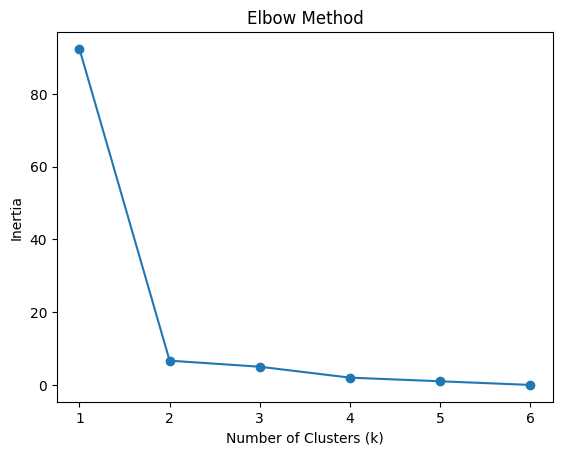

In [ ]:
X = np.array([
    [1, 8],
    [2, 7],
    [1, 6],
    [7, 2],
    [8, 1],
    [6, 3]
])


def calculate_distance(p1,p2):
  difference=p1-p2
  squared_diff=difference**2

  sum=np.sum(squared_diff)

  distance=np.sqrt(sum)

  return distance


def assign_clusters(X,centroids):

  clusters=[]

  for i in range(len(X)):
    distances=[]
    for j in range(len(centroids)):
      distance=calculate_distance(X[i],centroids[j])
      distances.append(distance)

    min_idx=np.argmin(distances)
    clusters.append(min_idx)

  return clusters


def update_centroids(X,clusters,k):
  new_centroids=[]

  for i in range(k):
    cluster_value=i
    cluster_points=[]


    for j in range(len(X)):


      if(clusters[j]==cluster_value):
        cluster_points.append(X[j])


    cluster_points=np.array(cluster_points)
    new_centroid=np.mean(cluster_points,axis=0)
    new_centroids.append(new_centroid)

  new_centroids=np.array(new_centroids)
  return new_centroids


def kmeans(X,k,epochs,tol):
  centroids=X[np.random.choice(range(len(X)),k,replace=False)]
  for epoch in range(epochs):
    clusters=assign_clusters(X,centroids)
    new_centroids=update_centroids(X,clusters,k)

    converged=True
    for i in range(k):
      if(calculate_distance(centroids[i],new_centroids[i])>tol):
        converged=False


    centroids=new_centroids
    if(converged==True):
      break
  return clusters,centroids

def inertia(X,clusters,centroids):
  inertia_vec=[]
  for i in range(len(X)):
    dist=calculate_distance(X[i],centroids[clusters[i]])

    dist=dist**2
    inertia_vec.append(dist)

  return np.sum(inertia_vec)

inertia_values = []

for k in range(1, 7):

    clusters, centroids = kmeans(
        X,
        k,
        100,
        0.0001
        )
    inertia_value = inertia(X, clusters, centroids)
    inertia_values.append(inertia_value)

print(inertia_values)


print("Cluster assignments:", clusters)
print("Final centroids:")
print(centroids)
import matplotlib.pyplot as plt

plt.plot(range(1, 7), inertia_values, marker='o')

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()





##PCA

In [ ]:
import numpy as np

def pca(X, n_components):
    # Step 1: Calculate the mean of each feature
    mean = np.mean(X, axis=0)

    # Step 2: Center the data
    X_centered = X - mean

    # Step 3: Calculate the covariance matrix
    cov_matrix = np.cov(X_centered, rowvar=False)

    # Step 4: Calculate eigenvalues and eigenvectors
    eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

    # Step 5: Sort components by eigenvalue, largest first
    sorted_indices = np.argsort(eigenvalues)[::-1]

    eigenvectors = eigenvectors[:, sorted_indices]

    # Step 6: Select the required number of components
    selected_components = eigenvectors[:, :n_components]

    # Step 7: Project the data onto the selected components
    X_reduced = X_centered @ selected_components

    return X_reduced